# Baseline: CNN Feature-Based Anomaly Detection

We use a pretrained ResNet18 to extract image-level features and detect anomalies based on their similarity to normal training examples.

The model learns normal appearance without using defective training images.

## Imports and Configs

In [18]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights

from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import json

from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score, average_precision_score, RocCurveDisplay

import dagshub
import mlflow

DATA_DIR = Path("../data/raw/metal_nut").resolve()
RESULTS_DIR = Path("../results/figures").resolve()

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

BATCH_SIZE = 16
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

print("Device:", DEVICE)
print("Dataset found:", DATA_DIR.exists())

Device: mps
Dataset found: True


## Experiment Tracking

In [19]:
dagshub.init(
    repo_owner="lchkh23",
    repo_name="inspectAI",
    mlflow=True
)

mlflow.set_experiment("metal-nut-anomaly-detection")

print("MLflow tracking initialized")

Initialized MLflow to track repo "lchkh23/inspectAI"

Repository lchkh23/inspectAI initialized!

MLflow tracking initialized


## Pretrained Feature Extractor

In [20]:
weights = ResNet18_Weights.DEFAULT

model = resnet18(weights=weights)

feature_extractor = nn.Sequential(
    *list(model.children())[:-1]
)

feature_extractor = feature_extractor.to(DEVICE)
feature_extractor.eval()

for param in feature_extractor.parameters():
    param.requires_grad = False

preprocess = weights.transforms()

print("Backbone: ResNet18")
print("Feature dimension: 512")

Backbone: ResNet18
Feature dimension: 512


## Dataset Preparation

In [21]:
class MetalNutDataset(Dataset):
    def __init__(self, root, split, transform):
        self.samples = []
        self.transform = transform

        split_dir = Path(root) / split

        for category_dir in sorted(split_dir.iterdir()):
            if not category_dir.is_dir():
                continue

            for image_path in sorted(category_dir.glob("*.png")):
                label = 0 if category_dir.name == "good" else 1
                self.samples.append(
                    (image_path, label, category_dir.name)
                )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label, category = self.samples[index]

        with Image.open(image_path) as img:
            image = self.transform(img.convert("RGB"))

        return image, label, category

In [22]:
# Full normal training dataset
full_train_dataset = MetalNutDataset(DATA_DIR, "train", preprocess)
test_dataset = MetalNutDataset(DATA_DIR, "test", preprocess)

# Reproducible 80/20 split
indices = np.arange(len(full_train_dataset))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=SEED,
    shuffle=True
)

train_dataset = Subset(full_train_dataset, sorted(train_idx))
val_dataset = Subset(full_train_dataset, sorted(val_idx))

assert set(train_idx).isdisjoint(set(val_idx))

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=False
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)

full_train_loader = DataLoader(
    full_train_dataset, batch_size=BATCH_SIZE, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Full training:", len(full_train_dataset))
print("Test:", len(test_dataset))

Train: 176
Validation: 44
Full training: 220
Test: 115


In [23]:
split_file = Path("../results/normal_split.json")

split_file.parent.mkdir(parents=True, exist_ok=True)

with open(split_file, "w") as f:
    json.dump({
        "seed": SEED,
        "train": [
            full_train_dataset.samples[i][0].name
            for i in sorted(train_idx)
        ],
        "validation": [
            full_train_dataset.samples[i][0].name
            for i in sorted(val_idx)
        ]
    }, f, indent=2)

print("Split saved:", split_file)

Split saved: ../results/normal_split.json


## Feature Extraction

In [24]:
@torch.inference_mode()
def extract_features(loader, model, device):
    all_features = []
    all_labels = []
    all_categories = []

    model.eval()

    for images, labels, categories in loader:
        images = images.to(device)

        features = model(images)
        features = features.flatten(start_dim=1)

        all_features.append(features.cpu().numpy())
        all_labels.extend(labels.numpy().tolist())
        all_categories.extend(categories)

    return (np.concatenate(all_features), np.array(all_labels), np.array(all_categories))


train_features, train_labels, train_categories = extract_features(train_loader, feature_extractor, DEVICE)
val_features, val_labels, val_categories = extract_features(val_loader, feature_extractor, DEVICE)
full_train_features, _, _ = extract_features(full_train_loader, feature_extractor, DEVICE)
test_features, test_labels, test_categories = extract_features(test_loader, feature_extractor, DEVICE)

print("Train features:", train_features.shape)
print("Validation features:", val_features.shape)
print("Full train features:", full_train_features.shape)
print("Test features:", test_features.shape)

Train features: (176, 512)
Validation features: (44, 512)
Full train features: (220, 512)
Test features: (115, 512)


## Nearest-Neighbor Anomaly Detection

In [25]:
run = mlflow.start_run(run_name="resnet18-knn-split-validated")

mlflow.log_params({
    "backbone": "resnet18",
    "pretrained": True,
    "feature_dim": 512,
    "input_size": 224,
    "method": "nearest_neighbor",
    "n_neighbors": 1,
    "distance_metric": "euclidean",
    "batch_size": BATCH_SIZE,
    "train_samples": len(train_dataset),
    "validation_samples": len(val_dataset),
    "final_train_samples": len(full_train_dataset),
    "test_samples": len(test_dataset),
    "validation_fraction": 0.2,
    "seed": SEED
})
mlflow.log_artifact(str(split_file), artifact_path="splits")

In [26]:
knn = NearestNeighbors(
    n_neighbors=1,
    metric="euclidean"
)

# Development: fit only on 176 training images
knn.fit(train_features)

val_distances, _ = knn.kneighbors(val_features)
val_scores = val_distances.flatten()

print(f"Validation mean anomaly score: {val_scores.mean():.4f}")
print(f"Validation 95th percentile: {np.percentile(val_scores, 95):.4f}")

mlflow.log_metric("validation_mean_score", float(val_scores.mean()))
mlflow.log_metric("validation_p95_score", float(np.percentile(val_scores, 95)))

# Final model: use all 220 original normal training images
knn.fit(full_train_features)

distances, indices = knn.kneighbors(test_features)
anomaly_scores = distances.flatten()

print("Test anomaly scores:", anomaly_scores.shape)

Validation mean anomaly score: 6.4138
Validation 95th percentile: 7.3910
Test anomaly scores: (115,)


In [27]:
image_auroc = roc_auc_score(test_labels, anomaly_scores)
image_ap = average_precision_score(test_labels, anomaly_scores)

mlflow.log_metrics({
    "image_auroc": float(image_auroc),
    "image_ap": float(image_ap)
})

print(f"Image AUROC: {image_auroc:.4f}")
print(f"Image AP: {image_ap:.4f}")

Image AUROC: 0.8109
Image AP: 0.9496


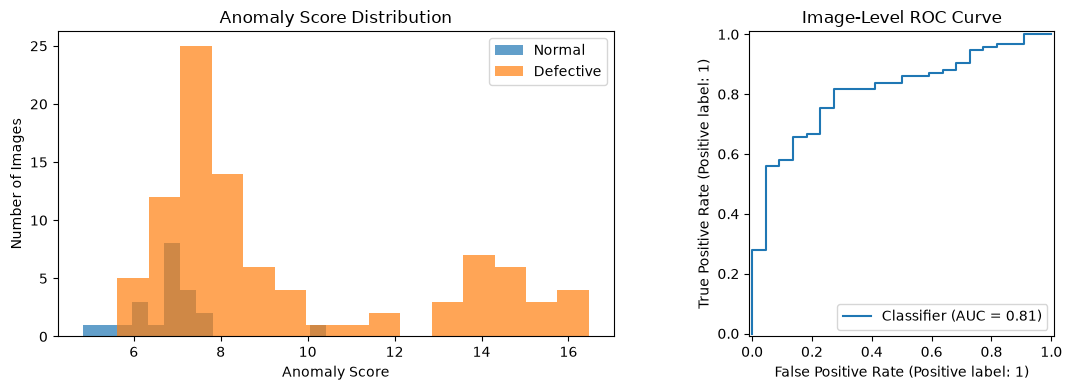

In [28]:
from sklearn.metrics import RocCurveDisplay

normal_scores = anomaly_scores[test_labels == 0]
defect_scores = anomaly_scores[test_labels == 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Anomaly score distributions
axes[0].hist(normal_scores, bins=15, alpha=0.7, label="Normal")
axes[0].hist(defect_scores, bins=15, alpha=0.7, label="Defective")

axes[0].set_title("Anomaly Score Distribution")
axes[0].set_xlabel("Anomaly Score")
axes[0].set_ylabel("Number of Images")
axes[0].legend()

# ROC curve
RocCurveDisplay.from_predictions(
    test_labels,
    anomaly_scores,
    ax=axes[1]
)

axes[1].set_title("Image-Level ROC Curve")

plt.tight_layout()
plt.show()

In [29]:
category_results = {}

for category in ["scratch", "bent", "color", "flip"]:
    mask = (
        (test_categories == "good") |
        (test_categories == category)
    )

    category_results[category] = roc_auc_score(
        test_labels[mask],
        anomaly_scores[mask]
    )

In [30]:
for category, score in category_results.items():
    mlflow.log_metric(f"auroc_{category}", float(score))

mlflow.log_figure(fig, "figures/baseline_evaluation.png")

mlflow.end_run()

print("Experiment logged successfully!")

🏃 View run resnet18-knn-split-validated at: https://dagshub.com/lchkh23/inspectAI.mlflow/#/experiments/1/runs/200392f9218e4fc7916d79a945d49ae9
🧪 View experiment at: https://dagshub.com/lchkh23/inspectAI.mlflow/#/experiments/1
Experiment logged successfully!


In [31]:
print(mlflow.active_run() is not None)

False


In [32]:
print("=== ResNet18 + KNN Baseline Results ===")

print(f"\nImage AUROC: {image_auroc:.4f}")
print(f"Image Average Precision: {image_ap:.4f}")

print("\nAUROC by Defect Type:")
for category, score in category_results.items():
    print(f"  {category.capitalize():8s}: {score:.4f}")

=== ResNet18 + KNN Baseline Results ===

Image AUROC: 0.8109
Image Average Precision: 0.9496

AUROC by Defect Type:
  Scratch : 0.8538
  Bent    : 0.7073
  Color   : 0.6860
  Flip    : 1.0000


## Baseline Results and Discussion

The ResNet18 + nearest-neighbor baseline achieved:

- **Image AUROC:** 0.8109
- **Average Precision:** 0.9496
- **Scratch AUROC:** 0.8538
- **Bent AUROC:** 0.7073
- **Color AUROC:** 0.6860
- **Flip AUROC:** 1.0000

### Key Findings

- Global CNN features successfully detect large appearance changes, particularly flipped objects.
- Performance is weaker for localized anomalies such as bending and color irregularities.
- The high Average Precision should be interpreted with caution due to the proportion of defective test images.
- The baseline provides image-level detection but does not localize defective regions.

### Next Steps

Implement PatchCore using pretrained intermediate CNN features and a memory bank of normal image patches. Evaluate whether patch-level representations improve detection of localized defects and enable pixel-level anomaly localization.